# Example: Calculate and Check the Greeks for Long and Short Options Contracts
The Greeks describe how an option's price changes with the underlying share price, volatility, time, and interest rate. In this example, we use the historical NVDA call and put contracts to compute these sensitivities, check the numerical calculation, and estimate the dollar exposure of a position.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Compute and interpret option sensitivities:__ Calculate the five Greeks for American calls and puts, distinguishing raw derivatives, daily quotes, and percentage-point quotes.
> * __Check numerical convergence:__ Compare CRR and Leisen–Reimer calculations against European formulas and a refined American reference, and examine the effects of tree depth and perturbation size.
> * __Use Greeks to assess a position:__ Convert long-option sensitivities into signed contract exposure, construct a local share hedge, and compare a delta–gamma price-change estimate with full repricing.

In this example, we retain the original market inputs and individual Greek calculations. We then use full-precision central differences to examine numerical accuracy and the resulting price-change estimates.

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the [Include.jl](Include.jl) file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, [Include.jl](Include.jl), in the notebook's global scope. The [Include.jl](Include.jl) file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Constants
We use the NVDA close and contract inputs from June 14, 2024. The original classroom rate is the June 13 ten-year Treasury yield; we retain it as a pricing proxy. A maturity-matched rate, dividend treatment, and the broker's numerical conventions would be needed to explain every difference from its quotes.

Let's set a one-calendar-day step in years, the risk-free rate, the underlying share price, and the number of CRR steps. Both contracts have 61 calendar days remaining, so 366 steps give six steps per calendar day. We use a zero dividend yield throughout this example: keeping the assumptions fixed lets us compare the numerical methods.

In [2]:
Δt = (1/365); # options use 365 day year
risk_free_rate = 0.0431; # yield 10-year treasury note on 13-Jun-2024
Sₒ = 131.88; # after close on 14-Jun-2024 (close: 131.88)
h = 366; # six steps per calendar day for the 61-day contracts

### Contract models
Next, we construct contract models for the options in this example. We begin by building an instance of the [MyAmericanCallContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanCallContractModel) using the [custom build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}). The [build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}) takes two arguments: the type to build, and a [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) containing the strike price `K`, the `premium` paid for the option, remaining time `DTE` in years, the `sense = 1` (long), the number of contracts in the `copy` field and the implied volatility in the `IV` field.

We save the call option contract model in the `call_option_model` variable:

In [3]:
call_option_model = build(MyAmericanCallContractModel, (
    K = 136.0, 
    premium = 9.23, # mark price
    DTE = (61.0)*Δt,
    sense = 1,
    copy = 1,
    IV = 0.4848
));

The put contract, which is an instance of the [MyAmericanPutContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel), is constructed in a similar way to the call option. We save the put option contract model in the `put_option_model` variable:

In [4]:
put_option_model = build(MyAmericanPutContractModel, (
    K = 128.0, 
    premium = 7.78, # mark price
    DTE = (61.0)*Δt,
    sense = 1,
    copy = 1,
    IV = 0.4787
));

__Note__: In both cases, we construct long contract models, i.e., we look at option dynamics from the perspective of a contract buyer. To convert to a short perspective, i.e., from the perspective of the contract seller, we multiply the Greek values by `-1` (see Task 3).

___

## Task 1: Compute the Greeks for a Long Call Option
In this task, we compute the five Greeks for the long call and compare numerical methods with the European analytic benchmark. Let's begin our examination of the Greeks by calculating the Greek values for a long call option. From the buyer's viewpoint, a long call option is a substitute for owning shares. The buyer speculates that the underlying share price will go up during the contract and hopes to profit from the increase in the option contract's price. 

However, the option contract price is a function of many different market factors, not just the share price of the underlying asset. The Greeks provide a quantitative means of computing the contract price's sensitivity to changes in market conditions.

Let's start our exploration of the Greeks by computing `delta` for the long call.

### Delta Long Call
Delta measures the rate of change in the option's premium $\mathcal{P}_{\tau}$ with respect to a `+1 USD/share` change in the underlying asset's price.
* We estimate $\Delta$ using the [delta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.delta). The [delta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.delta) takes several arguments: the `call_option_model` instance, and parameters used to compute the risk-neutral binomial share price tree, e.g., the number of tree levels `h,` the current share price  `Sₒ,` the remaining time `T` in years, etc.
* The [delta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.delta) returns a value for Delta. We store the estimated value for Delta in the `delta_long_call::Float64` variable:

So what do we get?

In [5]:
delta_long_call = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = call_option_model; # alias the contract model

    # call the greek function
    greek_value = delta(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

0.4920000000000009

__Summary__: For a long call, $\Delta_{c}\geq{0}$ implies that the option premium $\mathcal{P}_{c}$ increases with increasing share price. This underscores the use case of long call contracts as share replacements for underlying shares. 

> __Share-equivalent exposure:__
>
> The $\Delta_{c}$ of a contract can be used to compute the equivalent number of shares that the option represents, denoted as $n_{c}$ shares per contract:
>$$
\begin{align*}
n_{c} &= 100\cdot\Delta_{c}
\end{align*}
$$
> where $\Delta_{c}$ denotes the $\Delta$ value for a long call contract. 

The locally equivalent share exposure is positive; the share hedge for one long contract has the opposite sign. Thus, this long call contract has share-equivalent exposure of:

In [6]:
println("Number of share equivalents: $(delta_long_call*100) shares per contract")

Number of share equivalents: 49.20000000000009 shares per contract


#### Comparison: How close is the delta quote?
The historical long-call quote is `0.4979`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [7]:
observed_value_delta_long_call = let
    observed = 0.4979; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = delta_long_call;
    println("Call delta: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Call delta: computed = 0.492, quoted = 0.4979, difference = -0.0059, percentage difference = -1.185%


### Theta Long Call
Theta measures the rate of change in the option's premium $\mathcal{P}_{\tau}$ for a `1-day` decrease in the time to maturity of the contract.
* We estimate $\Theta$ using the [theta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.theta). The [theta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.theta) takes several arguments: the `call_option_model` instance, and parameters used to compute the risk-neutral binomial share price tree, e.g., the number of tree levels `h,` the current share price  `Sₒ,` the remaining time `T` in years.
* The [theta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.theta) returns a value for Theta. We store the estimated value for Theta in the `theta_long_call::Float64` variable:

What is our time decay estimate?

In [8]:
theta_long_call = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = call_option_model; # alias the contract model

    # call the greek function
    greek_value = theta(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

-0.09199999999999875

__Summary__: For this long call, a negative daily Theta quote implies that the option premium $\mathcal{P}_{c}$ decreases as we approach the expiration of the contract. Thus, all else being constant, this long call loses value as time passes under the stated model. This loss is referred to as the time decay of the long call contract. For the NVDA call contract, we have a time decay value of (units: USD per day per contract):

In [9]:
println("The long call changes in value: $(theta_long_call*100) USD per day per contract")

The long call changes in value: -9.199999999999875 USD per day per contract


#### Comparison: How close is the theta quote?
The historical long-call quote is `-0.0937`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [10]:
observed_value_theta_long_call = let
    observed = -0.0937; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = theta_long_call;
    println("Call theta: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Call theta: computed = -0.092, quoted = -0.0937, difference = 0.0017, percentage difference = 1.814%


### Vega Long Call
Vega measures the rate of change in the option's premium $\mathcal{P}_{\tau}$ with respect to a `+1 percentage-point` change in the underlying asset's implied volatility.
* We estimate $\nu$ using the [vega(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.vega). The [vega(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.vega) takes several arguments: the `call_option_model` instance, and several parameters used to compute the risk-neutral binomial share price tree, e.g., the number of tree levels `h,` the current share price  `Sₒ,` the remaining time `T` in years, etc.
* The [vega(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.vega) returns a value for Vega. We store the estimated value for vega in the `vega_long_call::Float64` variable:

So what is our volatility sensitivity estimate?

In [11]:
vega_long_call = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = call_option_model; # alias the contract model

    # call the Greek function -
    greek_value = vega(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

0.21600000000000108

__Summary__: For the long call contract, $\nu_{c}>0$. Thus, the option premium for this long call will increase with increasing implied volatility. In other words, as the uncertainty in the future share price increases (measured by the implied volatility), an option contract becomes more expensive. This makes sense as the option seller demands additional compensation for the additional risk.

#### Comparison: How close is the vega quote?
The historical long-call quote is `0.2159`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [12]:
observed_value_vega_long_call = let
    observed = 0.2159; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = vega_long_call;
    println("Call vega: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Call vega: computed = 0.216, quoted = 0.2159, difference = 0.0001, percentage difference = 0.046%


### Rho Long Call
Rho measures the rate of change in the option's premium $\mathcal{P}_{\tau}$ for a `+1 percentage-point` change in the risk-free rate $\bar{r}$. 
* We estimate $\rho$ using the [rho(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.rho). The [rho(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.rho) takes several arguments: the `call_option_model` instance, and several parameters used to compute the risk-neutral binomial share price tree, e.g., the number of tree levels `h,` the current share price  `Sₒ,` the remaining time `T` in years, etc.
* The [rho(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.rho) returns a value for $\rho$. We store the estimated value for $\rho$ in the `rho_long_call::Float64` variable:

So what is our interest rate sensitivity estimate?

In [13]:
rho_long_call = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = call_option_model; # alias the contract model

    # call the Greek function -
    greek_value = rho(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

0.0940000000000012

__Summary__: For a long call contract, $\rho_{c}>0$. Thus, the option premium increases with increasing risk-free rate. Under normal circumstances, the risk-free rate $\bar{r}$ doesn't significantly change. However, when interest rates increase during inflationary periods, a positive Rho shows that option premiums will increase, all else being equal.

In [14]:
println("Change in contract value by a one percentage-point increase in risk-free rate: $(rho_long_call*100) USD per contract")

Change in contract value by a one percentage-point increase in risk-free rate: 9.40000000000012 USD per contract


#### Comparison: How close is the rho quote?
The historical long-call quote is `0.095`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [15]:
observed_value_rho_long_call = let
    observed = 0.095; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = rho_long_call;
    println("Call rho: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Call rho: computed = 0.094, quoted = 0.095, difference = -0.001, percentage difference = -1.053%


### Gamma Long Call
Gamma is the last common Greek we'll explore. The $\Gamma$ measures the rate of change in Delta for a `+1 USD/share` change in the underlying price.
* We estimate $\Gamma$ using the [gamma(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.gamma). The [gamma(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.gamma) takes several arguments: the `call_option_model` instance, and several parameters used to compute the risk-neutral binomial share price tree, e.g., the number of tree levels `h,` the current share price  `Sₒ,` the remaining time `T` in years, etc.
* The [gamma(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.gamma) returns a value for $\Gamma$, which we store in the `gamma_long_call::Float64` variable:

What is our curvature estimate?

In [16]:
gamma_long_call = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = call_option_model; # alias the contract model

    # call the Greek function -
    greek_value = gamma(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

0.015270904088185067

__Summary__: The long call option has a $\Gamma_{c}>0$, which increases the premium's sensitivity to share price movements. The gamma value indicates how sensitive an option's delta is to changes in the underlying price, with higher gamma values indicating greater delta sensitivity.

#### Comparison: How close is the gamma quote?
The historical long-call quote is `0.0152`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [17]:
observed_value_gamma_long_call = let
    observed = 0.0152; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = gamma_long_call;
    println("Call gamma: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Call gamma: computed = 0.015271, quoted = 0.0152, difference = 7.1e-5, percentage difference = 0.466%


### Check convergence against a European benchmark
For the non-dividend call at a nonnegative interest rate, early exercise adds no value. We can therefore compare its American price and Greeks with the European BSM formulas stated in the lecture.

The [binomial_premium(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_premium) returns a full-precision per-share long value. The [binomial_greeks(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.binomial_greeks) returns raw central derivatives; `method=:crr` is the default, and `method=:leisen_reimer` selects the alternative tree. The contract position sign and multiplier are applied separately.

Let's evaluate the analytic call benchmark and then compare both methods at increasing odd step counts. The spot perturbation is one percent of the current share price; volatility and rate perturbations are decimal changes of 0.001 and 0.0001, respectively.

In [18]:
# Evaluate the non-dividend European BSM formulas from the lecture -
call_benchmark = let
    contract = call_option_model;
    τ, σ, K, r = contract.DTE, contract.IV, contract.K, risk_free_rate;
    d1 = (log(Sₒ/K) + (r+σ^2/2)*τ)/(σ*sqrt(τ));
    d2 = d1-σ*sqrt(τ);
    normal = Normal();
    (price=Sₒ*cdf(normal,d1)-K*exp(-r*τ)*cdf(normal,d2),
     delta=cdf(normal,d1), gamma=pdf(normal,d1)/(Sₒ*σ*sqrt(τ)),
     theta=-Sₒ*pdf(normal,d1)*σ/(2*sqrt(τ))-r*K*exp(-r*τ)*cdf(normal,d2),
     vega=Sₒ*pdf(normal,d1)*sqrt(τ), rho=K*τ*exp(-r*τ)*cdf(normal,d2))
end

(price = 9.036442161945331, delta = 0.49211007748591645, gamma = 0.015260370795778131, theta = -33.59789897332658, vega = 21.504163077339083, rho = 9.336014044577363)

In [19]:
call_convergence = let
    table = DataFrame();
    contract = call_option_model;
    for steps in (51,101,201,401,801), method in (:crr,:leisen_reimer)
        inputs = (method=method,h=steps,T=contract.DTE,σ=contract.IV,Sₒ=Sₒ,μ=risk_free_rate);
        value = binomial_premium(contract; inputs...);
        g = binomial_greeks(contract; inputs...);
        push!(table,(steps=steps,method=String(method),price=value,delta=g.delta,gamma=g.gamma,
            theta_day=g.theta/365,vega_point=g.vega/100,rho_point=g.rho/100,
            price_error=value-call_benchmark.price,delta_error=g.delta-call_benchmark.delta,
            gamma_error=g.gamma-call_benchmark.gamma));
    end
    last_lr = last(filter(:method => ==("leisen_reimer"),table));
    pretty_table(select(table,:steps,:method,:price_error,:delta_error,:gamma_error);
        fit_table_in_display_horizontally=false);
    quoted_reference=(call_benchmark.delta,call_benchmark.gamma,call_benchmark.theta/365,
        call_benchmark.vega/100,call_benchmark.rho/100);
    quoted_lr=(last_lr.delta,last_lr.gamma,last_lr.theta_day,last_lr.vega_point,last_lr.rho_point);
    comparison=DataFrame(greek=["delta","gamma","theta/day","vega/point","rho/point"],
        BSM=collect(quoted_reference),LR_801=collect(quoted_lr),
        difference=collect(quoted_lr).-collect(quoted_reference));
    println("Final Leisen–Reimer derivatives, using the lecture's quote scaling:")
    pretty_table(comparison;fit_table_in_display_horizontally=false);

    # checks -
    @assert abs(last_lr.price_error) < 1e-3
    @assert abs(last_lr.delta_error) < 5e-4
    @assert abs(last_lr.gamma_error) < 1e-4
    @assert isapprox(last_lr.theta_day,call_benchmark.theta/365;rtol=1e-3)
    @assert isapprox(last_lr.vega_point,call_benchmark.vega/100;rtol=1e-3)
    @assert isapprox(last_lr.rho_point,call_benchmark.rho/100;rtol=1e-3)

    # return -
    table
end;

┌───────┬───────────────┬──────────────┬─────────────┬─────────────┐
│ steps │        method │  price_error │ delta_error │ gamma_error │
│ Int64 │        String │      Float64 │     Float64 │     Float64 │
├───────┼───────────────┼──────────────┼─────────────┼─────────────┤
│    51 │           crr │    -0.031133 │  -0.0103427 │   0.0436373 │
│    51 │ leisen_reimer │ -0.000195609 │  -3.4033e-5 │ -2.03695e-6 │
│   101 │           crr │    0.0152561 │  -0.0172591 │  -0.0152604 │
│   101 │ leisen_reimer │  -5.06207e-5 │ -3.11679e-5 │ -2.76617e-6 │
│   201 │           crr │    0.0117457 │  0.00573306 │  -0.0152604 │
│   201 │ leisen_reimer │  -1.28793e-5 │ -3.04246e-5 │ -2.95522e-6 │
│   401 │           crr │  -0.00395341 │  7.45043e-5 │   0.0116956 │
│   401 │ leisen_reimer │  -3.24845e-6 │ -3.02352e-5 │ -3.00336e-6 │
│   801 │           crr │   0.00220196 │ -0.00226765 │ -0.00254283 │
│   801 │ leisen_reimer │  -8.15736e-7 │ -3.01874e-5 │ -3.01549e-6 │
└───────┴───────────────┴─────────


┌────────────┬───────────┬────────────┬─────────────┐
│      greek │       BSM │     LR_801 │  difference │
│     String │   Float64 │    Float64 │     Float64 │
├────────────┼───────────┼────────────┼─────────────┤
│      delta │   0.49211 │    0.49208 │ -3.01874e-5 │
│      gamma │ 0.0152604 │  0.0152574 │ -3.01549e-6 │
│  theta/day │ -0.092049 │ -0.0920518 │ -2.73263e-6 │
│ vega/point │  0.215042 │   0.215042 │ -2.52994e-8 │
│  rho/point │ 0.0933601 │  0.0933601 │ -1.91714e-9 │
└────────────┴───────────┴────────────┴─────────────┘


The first table separates price and derivative errors from the market-quote differences. Let's plot Delta and Gamma against the number of steps. The second table compares all five sensitivities using daily and percentage-point quote scaling. The dashed lines in the plots are the analytic BSM derivatives; look for a stable approach to those lines as the tree is refined.

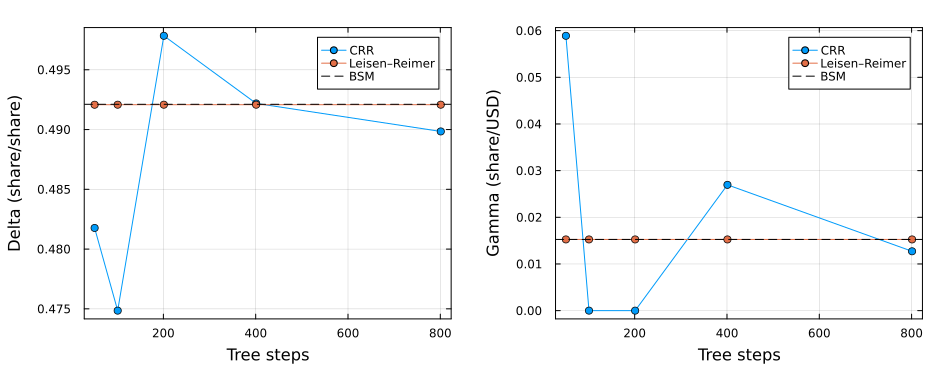

In [20]:
let
    panels = [];
    for (key,reference,label) in ((:delta,call_benchmark.delta,"Delta (share/share)"),
        (:gamma,call_benchmark.gamma,"Gamma (share/USD)"))
        p = plot(xlabel="Tree steps",ylabel=label,framestyle=:box,legend=:best);
        for method in ("crr","leisen_reimer")
            rows = filter(:method => ==(method),call_convergence);
            plot!(p,rows.steps,rows[!,key];marker=:circle,label=method == "crr" ? "CRR" : "Leisen–Reimer");
        end
        hline!(p,[reference];linestyle=:dash,color=:black,label="BSM");
        push!(panels,p);
    end
    plot(panels...;layout=(1,2),size=(950,370),margin=5Plots.mm)
end

__What do we see?__ The CRR central-difference results depend on how the perturbed share prices fall relative to terminal nodes. Leisen–Reimer is much closer to the analytic derivatives across these depths. We next examine the American put, where the early-exercise decision also affects the result.

___

## Task 2: Compute the Greeks for a Long Put Option
In this task, we compute the long put sensitivities and examine tree refinement, perturbation size, and changes in the underlying share price. Having computed all five Greeks for the long call contract, let's now examine how these values differ for a long put option. We'll compare the computed values with observed market data and contrast the results with those of the long call. Let's begin with Delta.

### Delta Long Put
Like the call option, we estimate $\Delta$ using the [delta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.delta), but in this case using the `put_option_model` instance, all other parameters held the same:

In [21]:
delta_long_put = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = put_option_model; # alias the contract model

    # call the Greek function -
    greek_value = delta(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

-0.3879999999999999

__Summary__: The $\Delta_{p}<0$ for the long put (opposite sign of the call). Thus, as the underlying share price increases, the value of the put option decreases. This is consistent with the notion that long puts make a bearish directional assumption, i.e., a buyer will purchase a put option if they believe the underlying asset's share price will decrease. 

> __What about the number of share equivalents?__ 
> The number of share equivalents for a long put, denoted as $n_{p}$, will be negative. The long put has the same local directional exposure as a short share position. A delta-neutral hedge therefore holds a positive number of shares against the long put. For this long put, we have $n_{p}$ defined as:
> $$
n_{p} = 100\cdot\Delta_{p}
$$
> where $\Delta_{p}$ denotes the $\Delta$ value for a long put contract. 

Thus, this long put contract is equivalent to:

In [22]:
println("Number of share equivalents for our long put: $(delta_long_put*100) shares per contract")

Number of share equivalents for our long put: -38.79999999999999 shares per contract


#### Comparison: How close is the delta quote?
The historical long-put quote is `-0.3847`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [23]:
observed_value_delta_long_put = let
    observed = -0.3847; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = delta_long_put;
    println("Put delta: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Put delta: computed = -0.388, quoted = -0.3847, difference = -0.0033, percentage difference = -0.858%


### Theta
Like the call option, we estimate $\Theta$ using the [theta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.theta), but in this case using the `put_option_model` instance, all other parameters held the same:

In [24]:
theta_long_put = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = put_option_model; # alias the contract model

    # call the Greek function -
    greek_value = theta(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

-0.07499999999999929

__Summary__: The $\Theta_{p}<0$ for the long put (same sign as the call option). Thus, these long call and long put contracts behave similarly in that the price of the option contract decreases as the contract approaches expiration, where all else is held constant.

In [25]:
println("The long put changes in value: $(theta_long_put*100) USD per day per contract")

The long put changes in value: -7.499999999999929 USD per day per contract


#### Comparison: How close is the theta quote?
The historical long-put quote is `-0.0726`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [26]:
observed_value_theta_long_put = let
    observed = -0.0726; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = theta_long_put;
    println("Put theta: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Put theta: computed = -0.075, quoted = -0.0726, difference = -0.0024, percentage difference = -3.306%


### Vega
Like the call option, we estimate `Vega` using the [vega(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.vega), but in this case using the `put_option_model` instance, all other parameters held the same:

In [27]:
vega_long_put = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = put_option_model; # alias the contract model

    # call the Greek function -
    greek_value = vega(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

0.20700000000000074

__Summary__: For the long put contract, $\nu_{p}>0$. Thus, the option premium for the long put (like the long call) will increase with implied volatility; as the uncertainty in the future share price increases (measured by the implied volatility), an option contract becomes more expensive (both calls and puts). This makes sense as the option seller will demand additional compensation for the additional risk.

#### Comparison: How close is the vega quote?
The historical long-put quote is `0.2068`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [28]:
observed_value_vega_long_put = let
    observed = 0.2068; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = vega_long_put;
    println("Put vega: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Put vega: computed = 0.207, quoted = 0.2068, difference = 0.0002, percentage difference = 0.097%


### Rho
Like the call option, we estimate $\rho$ using the [rho(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.rho), but in this case using the `put_option_model` instance, all other parameters held the same:

In [29]:
rho_long_put = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = put_option_model; # alias the contract model

    # call the Greek function -
    greek_value = rho(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end;

__Summary__: For a long put contract, $\rho_{p}<0$. Thus, the option premium decreases with increasing risk-free rate. Under normal circumstances, the risk-free rate $\bar{r}$ doesn't significantly change. However, when interest rates increase during inflationary periods, a negative $\rho$ shows that put option premiums will decrease, all else being equal.

In [30]:
println("Change in put contract price by a one percentage-point increase in risk-free rate: $(rho_long_put*100) USD per contract")

Change in put contract price by a one percentage-point increase in risk-free rate: -8.29999999999993 USD per contract


#### Comparison: How close is the rho quote?
The historical long-put quote is `-0.0902`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [31]:
observed_value_rho_long_put = let
    observed = -0.0902; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = rho_long_put;
    println("Put rho: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Put rho: computed = -0.083, quoted = -0.0902, difference = 0.0072, percentage difference = 7.982%


### Gamma
Finally, like the $\Gamma$ calculation for the long-call, we estimate $\Gamma$ using the [gamma(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.gamma), but in this case using the `put_option_model` instance, all other parameters held the same:

In [32]:
gamma_long_put = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = put_option_model; # alias the contract model

    # call the Greek function -
    greek_value = gamma(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

0.015050827534234618

__Summary__: The long put option has a $\Gamma_{p}>0$, which increases the premium's sensitivity to share price movements, i.e., the premium becomes more responsive to changes in share price. The Gamma value indicates how sensitive an option's Delta is to changes in the underlying price, with higher Gamma values indicating greater Delta sensitivity.

#### Comparison: How close is the gamma quote?
The historical long-put quote is `0.015`. Let's report the absolute and percentage differences from our calculation. The broker's inputs and numerical conventions can differ from ours, so this comparison describes quote agreement; the mathematical accuracy checks follow separately.

In [33]:
observed_value_gamma_long_put = let
    observed = 0.015; # historical per-share quote, using daily or percentage-point scaling where applicable
    computed = gamma_long_put;
    println("Put gamma: computed = ", round(computed; digits=6), ", quoted = ", observed,
        ", difference = ", round(computed-observed; digits=6),
        ", percentage difference = ", round(100*(computed-observed)/abs(observed); digits=3), "%")

    # return -
    observed
end;

Put gamma: computed = 0.015051, quoted = 0.015, difference = 5.1e-5, percentage difference = 0.339%


### Refine the American put reference
For the American put, the BSM European value is a lower bound under our assumptions. We compute Leisen–Reimer values at 1601 and 3201 steps, holding the finite-difference perturbations fixed. The difference between these refinements estimates the remaining numerical sensitivity; it does not supply an exact error bound.

In [34]:
put_refinement = let
    table = DataFrame();
    c = put_option_model;
    for steps in (1601,3201)
        inputs=(method=:leisen_reimer,h=steps,T=c.DTE,σ=c.IV,Sₒ=Sₒ,μ=risk_free_rate);
        value=binomial_premium(c;inputs...);
        g=binomial_greeks(c;inputs...);
        push!(table,(steps=steps,price=value,delta=g.delta,gamma=g.gamma,
            theta_day=g.theta/365,vega_point=g.vega/100,rho_point=g.rho/100));
    end
    pretty_table(table;fit_table_in_display_horizontally=false);
    println("Refinement differences: ",(; (key => table[2,key]-table[1,key] for key in propertynames(table)[2:end])...));

    # checks -
    @assert abs(table.price[2]-table.price[1]) < 0.005
    @assert abs(table.delta[2]-table.delta[1]) < 0.002
    @assert abs(table.gamma[2]-table.gamma[1]) < 0.002

    # return -
    table
end;

┌───────┬─────────┬───────────┬───────────┬────────────┬────────────┬────────────┐
│ steps │   price │     delta │     gamma │  theta_day │ vega_point │  rho_point │
│ Int64 │ Float64 │   Float64 │   Float64 │    Float64 │    Float64 │    Float64 │
├───────┼─────────┼───────────┼───────────┼────────────┼────────────┼────────────┤
│  1601 │ 7.92325 │ -0.390383 │ 0.0150379 │ -0.0751064 │   0.206608 │ -0.0844161 │
│  3201 │ 7.92318 │ -0.390384 │ 0.0150383 │ -0.0751057 │   0.206607 │ -0.0844212 │
└───────┴─────────┴───────────┴───────────┴────────────┴────────────┴────────────┘
Refinement differences: 

(price = -6.680110012524665e-5, delta = -9.596907968312252e-7, gamma = 4.4920597618534897e-7, theta_day = 6.980739670758851e-7, vega_point = -8.42023273328607e-7, rho_point = -5.087967869243926e-6)


The two reference rows should be close before we use the finer row for comparison. Let's vary both the step count and the spot perturbation. The perturbation sizes are expressed as fractions of the current share price; the reported derivatives keep their raw units.

In [35]:
put_convergence = let
    table=DataFrame();
    c=put_option_model;
    reference=last(put_refinement);
    for steps in (101,201,401,801), fraction in (0.005,0.01,0.02), method in (:crr,:leisen_reimer)
        g=binomial_greeks(c;method=method,h=steps,T=c.DTE,σ=c.IV,Sₒ=Sₒ,μ=risk_free_rate,
            spot_bump=fraction*Sₒ);
        push!(table,(steps=steps,spot_bump=fraction*Sₒ,method=String(method),delta=g.delta,gamma=g.gamma,
            delta_diff=g.delta-reference.delta,gamma_diff=g.gamma-reference.gamma));
    end
    pretty_table(table;fit_table_in_display_horizontally=false);

    # return -
    table
end;

┌───────┬───────────┬───────────────┬───────────┬─────────────┬──────────────┬──────────────┐
│ steps │ spot_bump │        method │     delta │       gamma │   delta_diff │   gamma_diff │
│ Int64 │   Float64 │        String │   Float64 │     Float64 │      Float64 │      Float64 │
├───────┼───────────┼───────────────┼───────────┼─────────────┼──────────────┼──────────────┤
│   101 │    0.6594 │           crr │ -0.372867 │  0.00145881 │    0.0175164 │   -0.0135795 │
│   101 │    0.6594 │ leisen_reimer │ -0.390292 │   0.0149915 │   9.16884e-5 │  -4.68205e-5 │
│   101 │    1.3188 │           crr │ -0.373558 │   0.0022219 │    0.0168261 │   -0.0128164 │
│   101 │    1.3188 │ leisen_reimer │ -0.390349 │   0.0150225 │   3.47288e-5 │  -1.58553e-5 │
│   101 │    2.6376 │           crr │ -0.391267 │   0.0149007 │ -0.000883137 │ -0.000137616 │
│   101 │    2.6376 │ leisen_reimer │ -0.390596 │   0.0150205 │ -0.000211798 │  -1.78125e-5 │
│   201 │    0.6594 │           crr │ -0.394042 │ 0.00084559

The reference uses the one-percent perturbation, so changes with perturbation size include finite-difference effects as well as tree error. To see whether small changes in the market input produce stable Greeks, let's also sweep the share price while holding the put's strike, maturity, and volatility fixed.

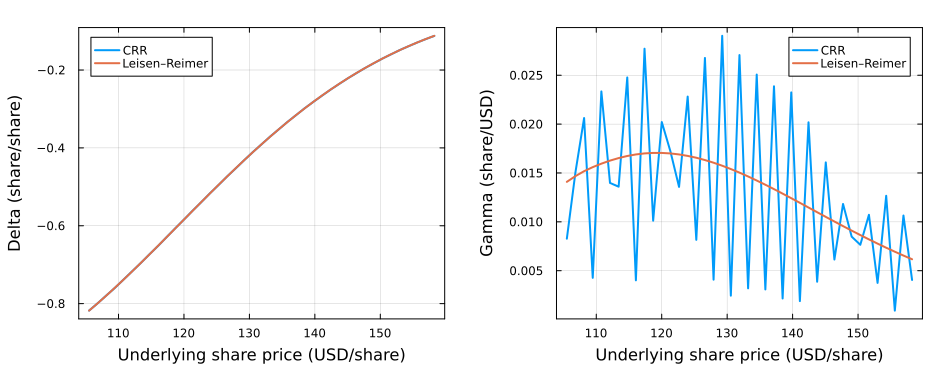

In [36]:
put_spot_sweep = let
    table=DataFrame();
    c=put_option_model;
    for spot in range(0.8Sₒ,1.2Sₒ;length=41), method in (:crr,:leisen_reimer)
        g=binomial_greeks(c;method=method,h=401,T=c.DTE,σ=c.IV,Sₒ=spot,μ=risk_free_rate);
        push!(table,(spot=spot,method=String(method),delta=g.delta,gamma=g.gamma));
    end

    # return -
    table
end;
let
    panels=[];
    for (key,label) in ((:delta,"Delta (share/share)"),(:gamma,"Gamma (share/USD)"))
        p=plot(xlabel="Underlying share price (USD/share)",ylabel=label,framestyle=:box,legend=:best);
        for method in ("crr","leisen_reimer")
            rows=filter(:method => ==(method),put_spot_sweep);
            plot!(p,rows.spot,rows[!,key];label=method == "crr" ? "CRR" : "Leisen–Reimer",linewidth=2);
        end
        push!(panels,p);
    end
    plot(panels...;layout=(1,2),size=(950,370),margin=5Plots.mm)
end

__What do we see?__ Compare the sensitivity to tree depth and perturbation size with the smoothness of the share-price sweep. Leisen–Reimer reduces the visible lattice oscillations in this case. The American exercise decision can still create changes in curvature, so use the refinement table to judge the numerical differences.

___

## Task 3: Convert the Greeks to Position Exposure and Estimate Price Changes
In this task, we convert the long-option Greeks to signed position exposure, calculate a share hedge, and compare local price-change estimates with full repricing. We computed Delta, Theta, Vega, Rho, and Gamma values for long put and call contracts in the previous tasks. The question now is, what about short contracts? Computing the Greek values for short contracts is straightforward: the Greek values for long and short contracts must sum to zero.


> __Greeks for Short Contracts__
>
> Denote the short value of a Greek by an overbar, i.e., the $\Delta$ for a short call contract evaluated at market conditions would be given by $\bar{\Delta}_{c}$. Then, the following condition must hold (for all market states):
> $$
\begin{align*}
\bar{\Delta}_{c} + \Delta_{c} = 0
\end{align*}
$$

It's important to note that the interconversion between long and short Greek values is a universal concept applicable to all the Greeks we have explored. This understanding will serve as a solid foundation for your options trading knowledge.

Unhide the code block below to see how we constructed a table for the Greeks for the long call NVDA contract.

In [37]:
let
    
    sense = -1;
    greek_dataframe = DataFrame();

    # delta -
    delta_row = (
        greek = "delta", 
        call_long_calc = delta_long_call,
        call_short_calc = (sense)*delta_long_call,
        check = delta_long_call + (sense)*delta_long_call,
        call_long_obs = observed_value_delta_long_call,
        quote_difference_pct = ((delta_long_call - observed_value_delta_long_call)/(observed_value_delta_long_call))*100
    )
    push!(greek_dataframe,delta_row);

    # theta
    theta_row = (
        greek = "theta", 
        call_long_calc = theta_long_call,
        call_short_calc = (sense)*theta_long_call,
        check = theta_long_call + (sense)*theta_long_call,
        call_long_obs = observed_value_theta_long_call,
        quote_difference_pct = ((theta_long_call - observed_value_theta_long_call)/(observed_value_theta_long_call))*100,
    )
    push!(greek_dataframe,theta_row);

    # vega -
    vega_row = (
        greek = "vega", 
        call_long_calc = vega_long_call,
        call_short_calc = (sense)*vega_long_call,
        check = vega_long_call + (sense)*vega_long_call,
        call_long_obs = observed_value_vega_long_call,
        quote_difference_pct = ((vega_long_call - observed_value_vega_long_call)/(observed_value_vega_long_call))*100
    )
    push!(greek_dataframe,vega_row);

    # rho -
    rho_row = (
        greek = "rho", 
        call_long_calc = rho_long_call,
        call_short_calc = (sense)*rho_long_call,
        check = rho_long_call + (sense)*rho_long_call,
        call_long_obs = observed_value_rho_long_call,
        quote_difference_pct = ((rho_long_call - observed_value_rho_long_call)/(observed_value_rho_long_call))*100
    )
    push!(greek_dataframe,rho_row);

    # gamma -
    gamma_row = (
        greek = "gamma", 
        call_long_calc = gamma_long_call,
        call_short_calc = (sense)*gamma_long_call,
        check = gamma_long_call + (sense)*gamma_long_call,
        call_long_obs = observed_value_gamma_long_call,
        quote_difference_pct = ((gamma_long_call - observed_value_gamma_long_call)/(observed_value_gamma_long_call))*100
    )
    push!(greek_dataframe,gamma_row);

    # display -
    pretty_table(
        greek_dataframe;
        
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact)
    );
end

 -------- ---------------- ----------------- --------- --------------- ----------------------
   greek   call_long_calc   call_short_calc     check   call_long_obs   quote_difference_pct 
  String          Float64           Float64   Float64         Float64                Float64 
 -------- ---------------- ----------------- --------- --------------- ----------------------
   delta            0.492            -0.492       0.0          0.4979               -1.18498
   theta           -0.092             0.092       0.0         -0.0937                -1.8143
    vega            0.216            -0.216       0.0          0.2159              0.0463177
     rho            0.094            -0.094       0.0           0.095               -1.05263
   gamma        0.0152709        -0.0152709       0.0          0.0152               0.466474
 -------- ---------------- ----------------- --------- --------------- ----------------------


and the NVDA put contract:

In [38]:
let
    
    sense = -1;
    greek_dataframe = DataFrame();

    # delta -
    delta_row = (
        greek = "delta", 
        put_long_calc = delta_long_put,
        put_short_calc = (sense)*delta_long_put,
        check = delta_long_put + (sense)*delta_long_put,
        put_long_obs = observed_value_delta_long_put,
        quote_difference_pct = ((delta_long_put - observed_value_delta_long_put)/(observed_value_delta_long_put))*100
    )
    push!(greek_dataframe,delta_row);

    # theta
    theta_row = (
        greek = "theta", 
        put_long_calc = theta_long_put,
        put_short_calc = (sense)*theta_long_put,
        check = theta_long_put + (sense)*theta_long_put,
        put_long_obs = observed_value_theta_long_put,
        quote_difference_pct = ((theta_long_put - observed_value_theta_long_put)/(observed_value_theta_long_put))*100,
    )
    push!(greek_dataframe,theta_row);

    # vega -
    vega_row = (
        greek = "vega", 
        put_long_calc = vega_long_put,
        put_short_calc = (sense)*vega_long_put,
        check = vega_long_put + (sense)*vega_long_put,
        put_long_obs = observed_value_vega_long_put,
        quote_difference_pct = ((vega_long_put - observed_value_vega_long_put)/(observed_value_vega_long_put))*100
    )
    push!(greek_dataframe,vega_row);

    # rho -
    rho_row = (
        greek = "rho", 
        put_long_calc = rho_long_put,
        put_short_calc = (sense)*rho_long_put,
        check = rho_long_put + (sense)*rho_long_put,
        put_long_obs = observed_value_rho_long_put,
        quote_difference_pct = ((rho_long_put - observed_value_rho_long_put)/(observed_value_rho_long_put))*100
    )
    push!(greek_dataframe,rho_row);

    # gamma -
    gamma_row = (
        greek = "gamma", 
        put_long_calc = gamma_long_put,
        put_short_calc = (sense)*gamma_long_put,
        check = gamma_long_put + (sense)*gamma_long_put,
        put_long_obs = observed_value_gamma_long_put,
        quote_difference_pct = ((gamma_long_put - observed_value_gamma_long_put)/(observed_value_gamma_long_put))*100
    )
    push!(greek_dataframe,gamma_row);

    # display -
    pretty_table(
        greek_dataframe;
        
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact)
    );
end

 -------- --------------- ---------------- --------- -------------- ----------------------
   greek   put_long_calc   put_short_calc     check   put_long_obs   quote_difference_pct 
  String         Float64          Float64   Float64        Float64                Float64 
 -------- --------------- ---------------- --------- -------------- ----------------------
   delta          -0.388            0.388       0.0        -0.3847               0.857811
   theta          -0.075            0.075       0.0        -0.0726                3.30579
    vega           0.207           -0.207       0.0         0.2068              0.0967118
     rho          -0.083            0.083       0.0        -0.0902               -7.98226
   gamma       0.0150508       -0.0150508       0.0          0.015                0.33885
 -------- --------------- ---------------- --------- -------------- ----------------------


__What do we see?__ The call and put tables show the sign reversal between long and short positions and the differences from the historical quotes. Gamma is now close to the quoted values with the current node-slope calculation. The original CRR Gamma uses node slopes and is already accurate for these contracts. The new study compares central differences with both tree models. It distinguishes convergence toward a mathematical reference from agreement with a broker quote. The price-change calculation shows why even a small Gamma can matter after multiplication by the squared share-price move and the contract multiplier.

### Compare a local price-change estimate with full repricing
Let's take one long NVDA call and use the 801-step Leisen–Reimer calculation. For a share-price move with the other inputs fixed, the lecture's local estimate is:

$$
\Delta\mathcal{P}_{c}\approx\Delta_c\Delta S+\frac12\Gamma_c(\Delta S)^2.
$$

We compare delta-only and delta–gamma estimates with the actual price change for moves of one, five, and ten dollars in either direction. The table reports USD per standard 100-share contract. The error columns show the estimate minus full repricing.

In [39]:
call_risk_greeks = binomial_greeks(call_option_model;method=:leisen_reimer,h=801,
    T=call_option_model.DTE,σ=call_option_model.IV,Sₒ=Sₒ,μ=risk_free_rate);
call_price_changes = let
    c=call_option_model;
    inputs=(method=:leisen_reimer,h=801,T=c.DTE,σ=c.IV,μ=risk_free_rate);
    base=binomial_premium(c;inputs...,Sₒ=Sₒ);
    table=DataFrame();
    for move in (-10.0,-5.0,-1.0,1.0,5.0,10.0)
        actual=100*(binomial_premium(c;inputs...,Sₒ=Sₒ+move)-base);
        linear=100*call_risk_greeks.delta*move;
        curved=linear+50*call_risk_greeks.gamma*move^2;
        push!(table,(spot_move=move,repriced_USD=actual,delta_USD=linear,delta_gamma_USD=curved,
            delta_error_USD=linear-actual,delta_gamma_error_USD=curved-actual));
    end
    pretty_table(table;fit_table_in_display_horizontally=false);
    hedge=-100*call_risk_greeks.delta;
    println("Share exposure of one long call: ",round(-hedge;digits=3)," shares")
    println("Share hedge for one long call: ",round(hedge;digits=3)," shares")

    # checks -
    @assert all(abs.(table.delta_gamma_error_USD) .< abs.(table.delta_error_USD))
    @assert abs(100*call_risk_greeks.delta+hedge) < 1e-10

    # return -
    table
end;

┌───────────┬──────────────┬───────────┬─────────────────┬─────────────────┬───────────────────────┐
│ spot_move │ repriced_USD │ delta_USD │ delta_gamma_USD │ delta_error_USD │ delta_gamma_error_USD │
│   Float64 │      Float64 │   Float64 │         Float64 │         Float64 │               Float64 │
├───────────┼──────────────┼───────────┼─────────────────┼─────────────────┼───────────────────────┤
│     -10.0 │     -415.008 │   -492.08 │        -415.793 │        -77.0717 │             -0.784904 │
│      -5.0 │     -226.819 │   -246.04 │        -226.968 │        -19.2208 │             -0.149149 │
│      -1.0 │     -48.4463 │   -49.208 │        -48.4451 │        -0.76165 │            0.00121765 │
│       1.0 │      49.9722 │    49.208 │         49.9709 │       -0.764214 │           -0.00134598 │
│       5.0 │      264.862 │    246.04 │         265.112 │        -18.8218 │              0.249876 │
│      10.0 │      565.892 │    492.08 │         568.367 │        -73.8118 │               

49.208 shares
Share hedge for one long call: -49.208 shares


__What do we see?__ Including Gamma improves the price-change estimate for these moves, and the residual grows as the move becomes larger. The share hedge cancels the local Delta contribution; the remaining curvature still changes the combined position's value.

For a joint market change, we must also include time, volatility, and interest rates. Let's compare the local approximation with a full repricing after one calendar day, a five-dollar share-price increase, a two-percentage-point increase in implied volatility, and a half-percentage-point increase in the risk-free rate.

In [40]:
let
    c=call_option_model;
    g=call_risk_greeks;
    move,vol_change,rate_change,elapsed=5.0,0.02,0.005,1/365;
    inputs=(method=:leisen_reimer,h=801);
    base=binomial_premium(c;inputs...,T=c.DTE,σ=c.IV,Sₒ=Sₒ,μ=risk_free_rate);
    changed=binomial_premium(c;inputs...,T=c.DTE-elapsed,σ=c.IV+vol_change,Sₒ=Sₒ+move,
        μ=risk_free_rate+rate_change);
    terms=(delta=g.delta*move,gamma=0.5*g.gamma*move^2,theta=g.theta*elapsed,
        vega=g.vega*vol_change,rho=g.rho*rate_change);
    table=DataFrame(term=String.(collect(keys(terms))),change_USD=100 .* collect(values(terms)));
    pretty_table(table;fit_table_in_display_horizontally=false);
    println("Local estimate: ",round(100*sum(values(terms));digits=3)," USD/contract")
    println("Full repricing: ",round(100*(changed-base);digits=3)," USD/contract")
    println("Estimate minus repricing: ",round(100*(sum(values(terms))-(changed-base));digits=3)," USD/contract")

    # return -
    nothing
end

┌────────┬────────────┐
│   term │ change_USD │
│ String │    Float64 │
├────────┼────────────┤
│  delta │     246.04 │
│  gamma │    19.0717 │
│  theta │   -9.20518 │
│   vega │    43.0083 │
│    rho │    4.66801 │
└────────┴────────────┘
Local estimate: 

303.583 USD/contract
Full repricing: 304.357 USD/contract
Estimate minus repricing: -0.774 USD/contract


The residual includes the cross derivatives and higher-order effects omitted from the local approximation. All five contributions use raw derivatives and decimal input changes, so each has units of USD/share before multiplication by 100. For a short contract, both the price change and every sensitivity contribution reverse sign.

___

## Summary
We computed the original NVDA call and put Greeks, checked full-precision CRR and Leisen–Reimer calculations, and used the results to assess a signed option position.

> __Key Takeaways:__
>
> * __Conventions connect derivatives to quoted exposure:__ We distinguished daily and percentage-point changes from raw derivatives, and applied the contract multiplier and position sign to obtain dollar exposure and the opposing share hedge.
> * __Convergence checks support a numerical choice:__ We compared European calculations with analytic formulas and American puts with a refined reference. Varying tree depth, perturbation size, and the share price showed where each method gave stable sensitivities.
> * __Curvature changes the price-change estimate:__ We compared delta-only and delta–gamma approximations with full repricing. Gamma's contribution grows with the square of the share-price move, while a share hedge offsets only the local first-order exposure.

Changing the contract inputs or numerical settings changes the reported results; use the same comparisons when exploring another contract.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___